# Tarea 2 · Parte 1: corpus y extracción (OCR + ASR)

**Fecha de extracción:** 26 de octubre de 2026

**Fuentes y licencias** (todas en Wikimedia Commons; el detalle por archivo está en `datos/fuentes.csv`):

| Corpus | Origen | Licencias |
|---|---|---|
| 8 impresos | Biblioteca Nacional del Perú y usuarios de Commons: diarios *El Comercio*, *El Tiempo* y *La Tribuna*, proclamas y oficios (1808–1945) | Dominio público, CC0, CC BY-SA 4.0 |
| 8 fotos | Usuarios de Commons: placas conmemorativas de Lima y cartas en exhibición | CC BY-SA 3.0/4.0, CC BY 2.0, CC0, dominio público |
| 9 manuscritos | Biblioteca Nacional del Perú (cartas a Ricardo Palma) y Academia Nacional de la Historia argentina (colección Fitte, sección Perú) | Dominio público, CC0 |
| 25 clips de audio | Entrevistas callejeras en Lima y el Callao (2022) y noticieros de la Biblioteca Nacional del Perú | CC BY-SA 4.0, CC BY 3.0, CC0 |

**Versiones**

| Componente | Versión |
|---|---|
| OCR | PaddleOCR 3.7.0 sobre PaddlePaddle 3.2.0 (CPU), `lang="es"`, modelos PP-OCRv5 |
| ASR | faster-whisper 1.2.1 (CTranslate2 4.8.4) con el modelo `large-v3`, `float16` en GPU |
| VAD | Silero, incluido en faster-whisper |
| Diarización | SpeechBrain 1.1.2 (`spkrec-ecapa-voxceleb`) + clustering aglomerativo; opcional pyannote.audio 4.0.7 |
| Seudonimización | spaCy 3.8 con `es_core_news_md` 3.8.0 |
| Python | 3.12, entorno con uv (`uv pip install -r requirements.txt`) |

```
cd tarea_2
uv venv --python 3.12
uv pip install -r requirements.txt
uv run python -m ipykernel install --user --name tarea2 --display-name "Python (tarea_2)"
```

In [1]:
import hashlib
import json
import os
import re
import subprocess
import sys
import time
from collections import Counter
from datetime import date
from io import BytesIO
from pathlib import Path

# torch va antes que paddle: si paddle se carga primero, torch no encuentra sus DLL de CUDA.
# Las DLL de cuBLAS y cuDNN que usa faster-whisper vienen en los paquetes nvidia-*.
import torch

for carpeta in Path(sys.prefix, "Lib", "site-packages", "nvidia").glob("*/bin"):
    os.add_dll_directory(str(carpeta))

import imageio_ffmpeg
import numpy as np
import pandas as pd
import plotly.express as px
import requests
from IPython.display import Image, display
from PIL import Image as PILImage

DATOS = Path("datos")
RAW_DOCS = DATOS / "raw" / "documentos"
RAW_AUDIO = DATOS / "raw" / "audio"
EJEMPLOS = DATOS / "ejemplos"
MODELOS = Path("modelos")
for carpeta in (RAW_DOCS, RAW_AUDIO, EJEMPLOS, MODELOS):
    carpeta.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_colwidth", 90)
px.defaults.template = "plotly_white"


def miniatura(ruta, ancho=360):
    im = PILImage.open(ruta).convert("RGB")
    im.thumbnail((ancho, ancho * 2))
    buf = BytesIO()
    im.save(buf, "JPEG", quality=80)
    return Image(buf.getvalue())

## 1. Recolección

Todo sale de Wikimedia Commons, con licencia libre:

- **Documentos**: 8 impresos (diarios, proclamas y oficios escaneados), 8 fotos con sombras, reflejos o inclinación
  (placas y cartas en exhibición) y 9 manuscritos (cartas y documentos de la Colonia al siglo XX, de la Biblioteca Nacional del Perú
  y de la colección Fitte de la Academia Nacional de la Historia argentina, sección Perú).
- **Una sola página por documento**: los PDF se bajan como la imagen de la página indicada, renderizada por Commons.
  Las imágenes se piden a 1920 px de ancho, uno de los tamaños estándar de Commons.
- **Audio**: 22 entrevistas callejeras en Lima y el Callao (entrevistador y entrevistado) y 3 noticieros narrados de la
  Biblioteca Nacional. Se baja la versión de video más liviana de Commons y se extrae el audio a WAV mono de 16 kHz.
  No se incluyen entrevistas sobre identidad de género u orientación sexual, porque son datos sensibles aunque la
  licencia permita usarlas.

Los archivos quedan en `datos/raw/` (fuera de Git). La celda no vuelve a bajar lo que ya existe.

In [2]:
API = "https://commons.wikimedia.org/w/api.php"
S = requests.Session()
S.headers["User-Agent"] = "qlabpucp-tarea2/0.1 (curso Python intermedio PUCP; github.com/vguardiaf)"

# (archivo en Commons, tipo, página del PDF)
DOCUMENTOS = [
    ("4000004161-0016 - Carta de Carlos J. Bachmann. 1914 julio 4, Maldonado; para Ricardo Palma, Lima.pdf", "impreso", 1),
    ("Ministerio de la Guerra y Marina-.jpg", "impreso", None),
    ("ElTiempo1895.jpg", "impreso", None),
    ("La Tribuna-1-edicion.jpg", "impreso", None),
    ("El Comercio - Lima. Perú y Ecuador. 3-3-1842.jpg", "impreso", None),
    ("El Comercio 1945.jpg", "impreso", None),
    ("Proclama Don Josef Fernando de Abascal y Sousa (1808).pdf", "impreso", 1),
    ("Portada de la Manifestación histórica y política de la revolución de América.jpg", "impreso", None),
    ("Carta de Felipe Santiago Salaverry a la seva esposa abans de la seva mort a Arequipa.jpg", "foto", None),
    ("Estado General de Miguel Grau.jpg", "foto", None),
    ("Exposición 100 años Armando Robles Godoy - Carta de Juan Velasco Alvarado.jpg", "foto", None),
    ("Carta de Grau a viuda de Prat en monumento chileno.JPG", "foto", None),
    ("Placa de la Casa Federico Elguera, Calle La Virreyna, Lima.jpg", "foto", None),
    ("Pasaje Acisclo Villarán - Placa conmemorativa.jpg", "foto", None),
    ("Placa conmemorativa Mercado Minorista La Parada.jpg", "foto", None),
    ("LimaPlacaCatedral1985.JPG", "foto", None),
    ("4000004161-0003 - Carta de Carlos J. Bachmann. 1912 junio 10, Riberalta; para Ricardo Palma, Lima.pdf", "manuscrito", 1),
    ("Carta de César Vallejo a José María Eguren.pdf", "manuscrito", 1),
    ("AR-ANH-EF-Secc.II-53-2.jpg", "manuscrito", None),
    ("AR-ANH-EF-Secc.II-64.jpg", "manuscrito", None),
    ("AR-ANH-EF-Secc.II-69.jpg", "manuscrito", None),
    ("Miguel Grau - Brev.jpg", "manuscrito", None),
    ("AR-ANH-EF-Secc.II-63.jpg", "manuscrito", None),
    ("AR-ANH-EF-Secc.II-22.pdf", "manuscrito", 1),
    ("AR-ANH-EF-Secc.V-53.jpg", "manuscrito", None),
]

AUDIOS = [
    "ENTREVISTA-3.webm",
    "ENTREVISTA A INTEGRANTE DE LA ASOCIACIÓN CORAZONES CHALACOS.webm",
    "Entrevista Por el día de la Independencia del Perú.webm",
    "Entrevista a Almirante de la Marina de Guerra del Perú (r) Luis Giampietri.webm",
    "Entrevista a señor presente en las manifestaciones durante las celebraciones del 28 de julio en Peru.webm",
    "Entrevista a transeúnte.webm",
    "Entrevista a un adulto mayor.webm",
    "Entrevista a un ciudadano por 28 de Julio (Fiestas Patrias en el Perú).webm",
    "Entrevista a un tatuador 01.webm",
    "Entrevista a una vendedora de chucherias.webm",
    "Entrevista con motivo de Fiestas Patrias Perú a persona líder en el apoyo a refugios animales.webm",
    "Entrevista con motivo del 201 aniversario de la independencia del Perú.webm",
    "Entrevista en Magdalena por Fiestas Patrias Perú 2022 (1).webm",
    "Entrevista en Magdalena por Fiestas Patrias Perú 2022 (2).webm",
    "Entrevista en Magdalena por Fiestas Patrias Perú 2022 (3).webm",
    'Entrevista por Fiestas Patrias - Feria Gastronómica "SABORES Y SABERES DEL PERÚ 2022".webm',
    'Entrevista por Fiestas Patrias - Feria Gastronómica "SABORES Y SABERES DEL PERÚ 2022" (02).webm',
    "Entrevista por el aniversario 201 de la independencia del Perú III.webm",
    "Entrevista por el aniversario de 201 de la independencia del Perú I.webm",
    "Entrevista a Alfredo López Morales, nieto de Don Juaquín Lopez Antay.webm",
    "Entrevista a José Beriche, artesano de escultura en madera, en la Feria Ruraq Maki.webm",
    "Entrevista a Roldán Pineda López, pintor artesano de Ucayali, desarrollada en el Ministerio de Cultura.webm",
    "Tarma, la ciudad florida de la sierra.webm",
    "Visiones de la provincia de Cajamarca.webm",
    "Visiones de la provincia de Huancayo.webm",
]


def consultar(**params):
    for intento in range(6):
        r = S.get(API, params={"action": "query", "format": "json", **params}, timeout=60)
        if r.ok and r.text.startswith("{"):
            return r.json()
        time.sleep(5 * (intento + 1))
    r.raise_for_status()


def bajar(url, destino):
    for intento in range(8):
        r = S.get(url, timeout=300)
        if r.status_code == 429:
            time.sleep(int(r.headers.get("retry-after", 0)) or 20 * (intento + 1))
            continue
        r.raise_for_status()
        destino.write_bytes(r.content)
        return
    raise RuntimeError(f"Commons sigue limitando la descarga de {url}")


def info(titulo, pagina=None):
    """URL de descarga y metadatos de licencia de un archivo de Commons."""
    params = {"titles": f"File:{titulo}", "prop": "imageinfo", "iiprop": "url|extmetadata"}
    es_imagen = not titulo.lower().endswith(".webm")
    if es_imagen:
        params |= {"iiurlwidth": 1920}
        if pagina:
            params |= {"iiurlparam": f"page{pagina}-1920px"}
    else:
        params |= {"prop": "videoinfo", "viprop": "url|extmetadata|derivatives"}
    p = next(iter(consultar(**params)["query"]["pages"].values()))
    ii = (p.get("imageinfo") or p.get("videoinfo") or [None])[0]
    if ii is None:
        raise KeyError(f"No existe en Commons: {titulo}")
    md = ii["extmetadata"]
    texto = lambda k: re.sub(r"<[^>]+>", "", md.get(k, {}).get("value", "")).strip()
    if es_imagen:
        url = ii["thumburl"]
    else:
        livianos = [d for d in ii["derivatives"] if d.get("transcodekey", "").endswith(".webm")]
        url = min(livianos, key=lambda d: d["bandwidth"])["src"] if livianos else ii["url"]
    return {"url": url.split("?")[0], "fuente_url": ii["descriptionurl"], "licencia": texto("LicenseShortName"),
            "autor": texto("Artist")[:120]}


def sha256(ruta):
    return hashlib.sha256(ruta.read_bytes()).hexdigest()


filas, hoy = [], date.today().isoformat()
for i, (titulo, tipo, pagina) in enumerate(DOCUMENTOS, 1):
    meta = info(titulo, pagina)
    destino = RAW_DOCS / f"doc_{i:03d}{Path(meta['url']).suffix.lower().replace('.jpeg', '.jpg')}"
    if not destino.exists():
        bajar(meta["url"], destino)
    filas.append({"id": f"doc_{i:03d}", "modalidad": "documento", "tipo": tipo, "archivo": destino.as_posix(),
                  "fuente_url": meta["fuente_url"], "licencia": meta["licencia"], "autor": meta["autor"],
                  "acceso": f"Wikimedia Commons, render de 1920 px{f'; página {pagina} del PDF' if pagina else ''}",
                  "sha256": sha256(destino), "fecha_extraccion": hoy})

ffmpeg = imageio_ffmpeg.get_ffmpeg_exe()
(RAW_AUDIO / "originales").mkdir(exist_ok=True)
for i, titulo in enumerate(AUDIOS, 1):
    meta = info(titulo)
    original = RAW_AUDIO / "originales" / f"clip_{i:03d}.webm"
    wav = RAW_AUDIO / f"clip_{i:03d}.wav"
    if not original.exists():
        bajar(meta["url"], original)
    if not wav.exists():
        subprocess.run([ffmpeg, "-y", "-loglevel", "error", "-i", str(original), "-vn", "-ac", "1", "-ar", "16000", str(wav)], check=True)
    filas.append({"id": f"clip_{i:03d}", "modalidad": "audio", "tipo": "entrevista" if "entrevista" in titulo.lower() else "noticiero",
                  "archivo": wav.as_posix(), "fuente_url": meta["fuente_url"], "licencia": meta["licencia"], "autor": meta["autor"],
                  "acceso": "Wikimedia Commons, versión webm más liviana; audio a WAV mono 16 kHz con ffmpeg",
                  "sha256": sha256(original), "fecha_extraccion": hoy})

fuentes = pd.DataFrame(filas)
pd.crosstab([fuentes.modalidad, fuentes.tipo], fuentes.licencia, margins=True, margins_name="total")

licencia              CC BY 2.0  CC BY 3.0  CC BY-SA 3.0  CC BY-SA 4.0  CC0  \
modalidad tipo                                                                
audio     entrevista          0          3             0            19    0   
          noticiero           0          0             0             0    3   
documento foto                1          0             1             4    1   
          impreso             0          0             0             1    2   
          manuscrito          0          0             0             0    1   
total                         1          3             1            24    7   

licencia              Public domain  total  
modalidad tipo                              
audio     entrevista              0     22  
          noticiero               0      3  
documento foto                    1      8  
          impreso                 5      8  
          manuscrito              8      9  
total                            14     50

## 2. OCR (Sesión 10)

PaddleOCR con `lang="es"`, una página por documento:

- **Orientación y enderezado** de la página (`use_doc_orientation_classify`, `use_doc_unwarping`) y orientación de
  cada línea (`use_textline_orientation`), para las fotos inclinadas y los manuscritos torcidos.
- **Fotos**: antes del OCR, escala de grises y CLAHE (`clipLimit=2`, `tileGridSize=8×8`) para bajar sombras y reflejos.
- **Respaldo** en `datos/raw/documentos/`: JSON crudo con cajas, textos y confianzas (`ocr/`), un recorte por línea
  (`recortes/`) y la imagen preprocesada de las fotos (`pre/`).
- La configuración queda en `modelos/config_ocr.json`. Si el JSON de un documento ya existe, no se vuelve a procesar
  (en CPU toma unos 2 minutos por página).

In [3]:
import cv2
import paddle
import paddleocr

PARAMS_OCR = {"lang": "es", "use_doc_orientation_classify": True, "use_doc_unwarping": True, "use_textline_orientation": True}
PRE_FOTO = {"escala": "grises", "clahe_clip_limit": 2.0, "clahe_tile_grid": [8, 8]}
MODELO_OCR = f"PaddleOCR {paddleocr.__version__} (lang=es, orientación y enderezado de página; CLAHE en fotos)"
json.dump({"modelo": MODELO_OCR, "paddleocr": paddleocr.__version__, "paddlepaddle": paddle.__version__, "dispositivo": "cpu", "parametros": PARAMS_OCR, "preprocesamiento_fotos": PRE_FOTO},
          open(MODELOS / "config_ocr.json", "w", encoding="utf-8"), ensure_ascii=False, indent=2)


def preprocesar_foto(ruta):
    gris = cv2.cvtColor(cv2.imread(str(ruta)), cv2.COLOR_BGR2GRAY)
    clahe = cv2.createCLAHE(clipLimit=PRE_FOTO["clahe_clip_limit"], tileGridSize=tuple(PRE_FOTO["clahe_tile_grid"])).apply(gris)
    salida = RAW_DOCS / "pre" / f"{ruta.stem}.png"
    salida.parent.mkdir(exist_ok=True)
    cv2.imwrite(str(salida), cv2.cvtColor(clahe, cv2.COLOR_GRAY2BGR))
    return salida


def guardar_recortes(doc_id, imagen, polys):
    carpeta = RAW_DOCS / "recortes" / doc_id
    carpeta.mkdir(parents=True, exist_ok=True)
    for k, poly in enumerate(polys):
        x, y, w, h = cv2.boundingRect(np.asarray(poly, dtype=np.int32))
        if w > 0 and h > 0:
            cv2.imwrite(str(carpeta / f"linea_{k:03d}.png"), imagen[y:y + h, x:x + w])


(RAW_DOCS / "ocr").mkdir(exist_ok=True)
ocr = None
resultados = []
for doc in fuentes[fuentes.modalidad == "documento"].itertuples():
    crudo = RAW_DOCS / "ocr" / f"{doc.id}.json"
    if not crudo.exists():
        if ocr is None:
            ocr = paddleocr.PaddleOCR(**PARAMS_OCR)
        entrada = preprocesar_foto(Path(doc.archivo)) if doc.tipo == "foto" else Path(doc.archivo)
        res = ocr.predict(str(entrada))[0]
        res.save_to_json(str(crudo))
        # las cajas están en coordenadas de la página ya enderezada
        imagen = res["doc_preprocessor_res"]["output_img"] if res.get("doc_preprocessor_res") else cv2.imread(str(entrada))
        guardar_recortes(doc.id, imagen, res["rec_polys"])
    r = json.load(open(crudo, encoding="utf-8"))
    resultados.append({"id": doc.id, "texto_ocr": " ".join(r["rec_texts"]), "n_lineas": len(r["rec_texts"]),
                       "conf_media": float(np.mean(r["rec_scores"])) if r["rec_scores"] else 0.0})
del ocr

docs = fuentes[fuentes.modalidad == "documento"].merge(pd.DataFrame(resultados), on="id").assign(modelo_ocr=MODELO_OCR)
docs["n_caracteres"] = docs.texto_ocr.str.len()
print(MODELO_OCR)
docs.groupby("tipo")[["n_lineas", "n_caracteres", "conf_media"]].median().round(2)

C:\Users\victo\Documents\GitHub\qlabpucp_python_intermedio\tarea_2\.venv\Lib\site-packages\paddle\utils\cpp_extension\extension_utils.py:718: UserWarning: No ccache found. Please be aware that recompiling all source files may be required. You can download and install ccache from: https://github.com/ccache/ccache/blob/master/doc/INSTALL.md
  warnings.warn(warning_message)


C:\Users\victo\Documents\GitHub\qlabpucp_python_intermedio\tarea_2\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


PaddleOCR 3.7.0 (lang=es, orientación y enderezado de página; CLAHE en fotos)


,n_lineas,n_caracteres,conf_media
tipo,,,
foto,16.5,392.5,0.83
impreso,84.0,3021.5,0.96
manuscrito,22.0,546.0,0.70


doc_001 · impreso · 26 líneas · confianza media 0.96


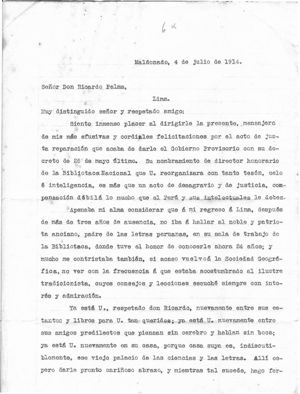

doc_009 · foto · 33 líneas · confianza media 0.82


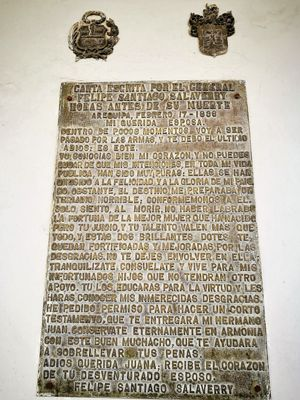

doc_017 · manuscrito · 54 líneas · confianza media 0.51


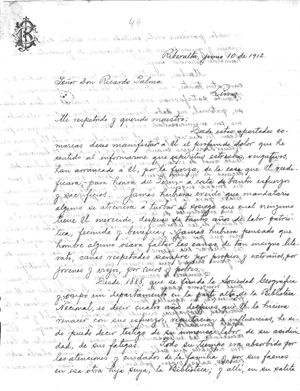

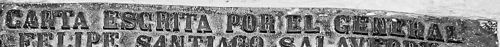

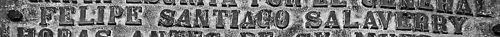

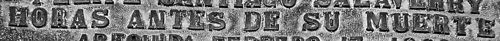

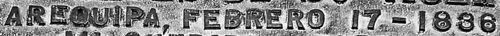

In [4]:
# Un ejemplo de cada tipo y los primeros recortes de línea de una foto
for tipo in ["impreso", "foto", "manuscrito"]:
    d = docs[docs.tipo == tipo].iloc[0]
    print(f"{d.id} · {tipo} · {d.n_lineas} líneas · confianza media {d.conf_media:.2f}")
    display(miniatura(d.archivo, 300))
foto = docs[docs.tipo == "foto"].iloc[0].id
for recorte in sorted((RAW_DOCS / "recortes" / foto).glob("*.png"))[:4]:
    display(miniatura(recorte, 500))

## 3. ASR (Sesión 13)

Mismo flujo que `voz.py` de la sesión:

1. **VAD**: filtro Silero de faster-whisper; un silencio de 500 ms o más corta el segmento.
2. **Transcripción**: faster-whisper `large-v3` en GPU (`float16`, `beam_size=5`), con el idioma detectado por clip.
3. **Diarización** de todos los clips: embeddings ECAPA de SpeechBrain por segmento y clustering aglomerativo por
   distancia coseno (umbral 0.7). Si existe la variable `HF_TOKEN`, se usa `pyannote/speaker-diarization-community-1`.
4. **Exportación** por clip a SRT, TXT y CSV de segmentos en `datos/raw/audio/salidas/` (fuera de Git, como los videos y
   los WAV). La configuración queda en `modelos/config_asr.json`. Los clips ya transcritos no se reprocesan.

In [5]:
import faster_whisper
import soundfile as sf
from faster_whisper import WhisperModel
from sklearn.cluster import AgglomerativeClustering

SALIDAS = RAW_AUDIO / "salidas"
SALIDAS.mkdir(exist_ok=True)
PARAMS_ASR = {"modelo": "large-v3", "device": "cuda", "compute_type": "float16", "beam_size": 5,
              "vad_filter": True, "min_silence_duration_ms": 500}
PARAMS_DIAR = {"umbral_coseno": 0.7, "min_segmento_embedding_s": 1.0, "min_voz_por_hablante_s": 5.0}
HF_TOKEN = os.environ.get("HF_TOKEN")
DIARIZACION = "pyannote/speaker-diarization-community-1" if HF_TOKEN else "SpeechBrain ECAPA + clustering aglomerativo"
MODELO_ASR = f"faster-whisper {PARAMS_ASR['modelo']} (VAD on)"
json.dump({"modelo": MODELO_ASR, "faster_whisper": faster_whisper.__version__, "asr": PARAMS_ASR, "diarizacion": DIARIZACION, "parametros_diarizacion": PARAMS_DIAR},
          open(MODELOS / "config_asr.json", "w", encoding="utf-8"), ensure_ascii=False, indent=2)


def diarizar_ecapa(audio, sr, segmentos, encoder):
    utiles = [k for k, s in enumerate(segmentos) if s.end - s.start >= PARAMS_DIAR["min_segmento_embedding_s"]]
    if len(utiles) < 2:
        return [0] * len(segmentos)
    embs = np.stack([encoder.encode_batch(torch.tensor(audio[int(segmentos[k].start * sr):int(segmentos[k].end * sr)]).unsqueeze(0))
                     .squeeze().cpu().numpy() for k in utiles])
    embs /= np.linalg.norm(embs, axis=1, keepdims=True)
    grupos = AgglomerativeClustering(n_clusters=None, metric="cosine", linkage="average",
                                     distance_threshold=PARAMS_DIAR["umbral_coseno"]).fit_predict(embs)
    etiquetas = [None] * len(segmentos)
    for k, g in zip(utiles, grupos):
        etiquetas[k] = int(g)
    for k in range(len(segmentos)):  # los segmentos cortos heredan el hablante del segmento útil más cercano
        if etiquetas[k] is None:
            etiquetas[k] = etiquetas[min(utiles, key=lambda u: abs(segmentos[u].start - segmentos[k].start))]
    return etiquetas


def diarizar_pyannote(ruta, segmentos, pipeline):
    turnos = [(t.start, t.end, h) for t, _, h in pipeline(str(ruta)).speaker_diarization.itertracks(yield_label=True)]
    etiquetas = []
    for s in segmentos:  # el hablante que más se solapa con cada segmento de Whisper
        solape = Counter()
        for ini, fin, h in turnos:
            solape[h] += max(0, min(s.end, fin) - max(s.start, ini))
        etiquetas.append(solape.most_common(1)[0][0] if solape and solape.most_common(1)[0][1] > 0 else None)
    return etiquetas


def renombrar(etiquetas, segmentos):
    """HABLANTE_1, HABLANTE_2... por orden de aparición; no cuenta a quien habla menos de 5 s."""
    total = Counter()
    for e, s in zip(etiquetas, segmentos):
        total[e] += s.end - s.start
    orden = [e for e in dict.fromkeys(etiquetas) if e is not None and total[e] >= PARAMS_DIAR["min_voz_por_hablante_s"]]
    nombres = {e: f"HABLANTE_{i}" for i, e in enumerate(orden, 1)}
    return [nombres.get(e, "HABLANTE_?") for e in etiquetas], len(orden)


def tiempo_srt(t):
    h, resto = divmod(t, 3600)
    m, s = divmod(resto, 60)
    return f"{int(h):02d}:{int(m):02d}:{s:06.3f}".replace(".", ",")


def exportar(clip_id, segmentos, hablantes):
    tabla = pd.DataFrame({"inicio": [round(s.start, 2) for s in segmentos], "fin": [round(s.end, 2) for s in segmentos],
                          "hablante": hablantes, "texto": [s.text.strip() for s in segmentos]})
    tabla.to_csv(SALIDAS / f"{clip_id}.csv", index=False)
    srt = [f"{i}\n{tiempo_srt(r.inicio)} --> {tiempo_srt(r.fin)}\n[{r.hablante}] {r.texto}\n" for i, r in enumerate(tabla.itertuples(), 1)]
    (SALIDAS / f"{clip_id}.srt").write_text("\n".join(srt), encoding="utf-8")
    turnos, actual = [], None
    for r in tabla.itertuples():  # TXT: un párrafo por turno de habla
        if r.hablante != actual:
            turnos.append(f"[{r.hablante}] {r.texto}")
            actual = r.hablante
        else:
            turnos[-1] += f" {r.texto}"
    (SALIDAS / f"{clip_id}.txt").write_text("\n\n".join(turnos), encoding="utf-8")


resumen_asr = RAW_AUDIO / "asr_resultados.csv"
previos = pd.read_csv(resumen_asr) if resumen_asr.exists() else pd.DataFrame(columns=["id"])
pendientes = fuentes[(fuentes.modalidad == "audio") & ~fuentes.id.isin(previos.id)]
filas_asr = []
if len(pendientes):
    whisper = WhisperModel(PARAMS_ASR["modelo"], device=PARAMS_ASR["device"], compute_type=PARAMS_ASR["compute_type"])
    if HF_TOKEN:
        from pyannote.audio import Pipeline
        pipeline = Pipeline.from_pretrained("pyannote/speaker-diarization-community-1", token=HF_TOKEN).to(torch.device("cuda"))
    else:
        from speechbrain.inference.speaker import EncoderClassifier
        from speechbrain.utils.fetching import LocalStrategy
        encoder = EncoderClassifier.from_hparams("speechbrain/spkrec-ecapa-voxceleb", savedir=str(RAW_AUDIO / "modelos" / "ecapa"),
                                                 run_opts={"device": "cuda"}, local_strategy=LocalStrategy.COPY)
    for clip in pendientes.itertuples():
        audio, sr = sf.read(clip.archivo, dtype="float32")  # ya es mono a 16 kHz, lo que espera Whisper
        segs, info_asr = whisper.transcribe(audio, beam_size=PARAMS_ASR["beam_size"], vad_filter=True,
                                            vad_parameters={"min_silence_duration_ms": PARAMS_ASR["min_silence_duration_ms"]})
        segs = list(segs)
        n = 0
        if segs:
            etiquetas = diarizar_pyannote(clip.archivo, segs, pipeline) if HF_TOKEN else diarizar_ecapa(audio, sr, segs, encoder)
            hablantes, n = renombrar(etiquetas, segs)
            exportar(clip.id, segs, hablantes)
        filas_asr.append({"id": clip.id, "duracion_seg": round(info_asr.duration, 1), "voz_seg": round(info_asr.duration_after_vad, 1),
                          "idioma": info_asr.language, "prob_idioma": round(info_asr.language_probability, 3), "n_hablantes": n})
        print(f"{clip.id} {info_asr.duration:6.1f} s (voz {info_asr.duration_after_vad:6.1f} s) {info_asr.language} {n} hablantes")
    del whisper
    torch.cuda.empty_cache()
    previos = pd.concat([previos, pd.DataFrame(filas_asr)], ignore_index=True)
    previos.to_csv(resumen_asr, index=False)


def texto_clip(clip_id):
    """Turnos del TXT unidos en una línea, con las marcas de hablante."""
    txt = SALIDAS / f"{clip_id}.txt"
    return " ".join(txt.read_text(encoding="utf-8").split("\n\n")) if txt.exists() else ""


clips = fuentes[fuentes.modalidad == "audio"].merge(previos, on="id").assign(modelo_asr=MODELO_ASR)
clips["texto_asr"] = clips.id.map(texto_clip)
clips["n_palabras"] = clips.texto_asr.str.replace(r"\[HABLANTE_[\d?]+\]", "", regex=True).str.split().str.len()
print(MODELO_ASR)
print(f"{len(clips)} clips · {clips.duracion_seg.sum() / 60:.1f} min de audio · {clips.voz_seg.sum() / 60:.1f} min con voz")
clips[["id", "tipo", "duracion_seg", "voz_seg", "idioma", "prob_idioma", "n_hablantes", "n_palabras"]]

faster-whisper large-v3 (VAD on)
25 clips · 68.4 min de audio · 56.9 min con voz


,id,tipo,duracion_seg,voz_seg,idioma,prob_idioma,n_hablantes,n_palabras
0,clip_001,entrevista,165.4,151.3,es,0.960,2.0,407
1,clip_002,entrevista,94.5,74.6,es,0.986,2.0,150
2,clip_003,entrevista,104.2,96.7,es,0.878,2.0,202
3,clip_004,entrevista,140.8,137.8,es,0.997,2.0,250
4,clip_005,entrevista,181.2,176.1,es,0.994,2.0,480
5,clip_006,entrevista,98.2,86.3,es,0.944,2.0,149
6,clip_007,entrevista,289.3,276.2,es,0.952,2.0,610
7,clip_008,entrevista,187.1,180.8,es,0.998,2.0,411
8,clip_009,entrevista,110.1,100.0,es,0.941,2.0,184
9,clip_010,entrevista,207.8,189.2,es,0.982,2.0,395


## 4. Limpieza

Se descartan:

- **Duplicados**: dos archivos con el mismo SHA-256.
- **Documentos ilegibles**: menos de 40 caracteres reconocidos o confianza media del OCR menor a 0.5.
- **Audios sin voz**: menos del 20 % del clip con voz según el VAD, sin texto, menos de 0.3 palabras por segundo de voz
  (señal de música o ruido sobre el que Whisper inventa frases sueltas) o en un idioma distinto al español.

Cada descarte se reemplaza en las listas de la sección 1 por otro archivo de Commons hasta volver a cumplir los
mínimos (25 documentos: 8 impresos, 8 fotos y 9 manuscritos; 20 clips y 30 minutos).

In [6]:
MIN_CARACTERES, MIN_CONF, MIN_VOZ, MIN_PALABRAS_SEG = 40, 0.5, 0.2, 0.3

descartes = [{"id": r.id, "modalidad": r.modalidad, "motivo": "duplicado (mismo SHA-256)"}
             for r in fuentes[fuentes.duplicated("sha256", keep="first")].itertuples()]
for d in docs.itertuples():
    if d.n_caracteres < MIN_CARACTERES:
        descartes.append({"id": d.id, "modalidad": "documento", "motivo": f"ilegible: {d.n_caracteres} caracteres"})
    elif d.conf_media < MIN_CONF:
        descartes.append({"id": d.id, "modalidad": "documento", "motivo": f"ilegible: confianza {d.conf_media:.2f}"})
for c in clips.itertuples():
    if c.n_palabras == 0 or c.voz_seg / c.duracion_seg < MIN_VOZ:
        descartes.append({"id": c.id, "modalidad": "audio", "motivo": f"sin voz: {c.voz_seg / c.duracion_seg:.0%} con voz"})
    elif c.n_palabras / c.voz_seg < MIN_PALABRAS_SEG:
        descartes.append({"id": c.id, "modalidad": "audio",
                          "motivo": f"sin voz útil: {c.n_palabras} palabras en {c.voz_seg:.0f} s (música; Whisper alucina)"})
    elif c.idioma != "es":
        descartes.append({"id": c.id, "modalidad": "audio", "motivo": f"idioma detectado: {c.idioma}"})
descartes = pd.DataFrame(descartes, columns=["id", "modalidad", "motivo"])
print(f"Descartados: {len(descartes)}")
display(descartes)

docs = docs[~docs.id.isin(descartes.id)].reset_index(drop=True)
clips = clips[~clips.id.isin(descartes.id)].reset_index(drop=True)
por_tipo = docs.tipo.value_counts()
for tipo, minimo in {"impreso": 8, "foto": 8, "manuscrito": 9}.items():
    print(f"{tipo:11} {por_tipo.get(tipo, 0):3d} / {minimo}   {'OK' if por_tipo.get(tipo, 0) >= minimo else 'FALTA'}")
print(f"{'clips':11} {len(clips):3d} / 20   {'OK' if len(clips) >= 20 else 'FALTA'}")
print(f"{'minutos':11} {clips.duracion_seg.sum() / 60:5.1f} / 30 {'OK' if clips.duracion_seg.sum() >= 1800 else 'FALTA'}")

Descartados: 1


,id,modalidad,motivo
0,clip_012,audio,sin voz útil: 3 palabras en 68 s (música; Whisper alucina)


impreso       8 / 8   OK
foto          8 / 8   OK
manuscrito    9 / 9   OK
clips        24 / 20   OK
minutos      66.8 / 30 OK


## 5. Seudonimización

Antes de mostrar o publicar cualquier texto se reemplazan:

- **Identificadores**, con reglas: correos, RUC (11 dígitos), DNI (8 dígitos) y celulares peruanos.
- **Nombres de personas**, con el NER de spaCy `es_core_news_md` (entidades `PER`). Antes, las palabras en mayúsculas
  pasan a formato título para que el NER las reconozca. Después, se descartan las detecciones que no parecen nombres
  (el ruido del OCR que el NER toma por personas) y se dejan fuera los tratamientos ("Señor Don", "General").
- **Presentaciones** en las entrevistas ("mi nombre es…", "me llamo…", "¿cuál es su nombre? …"): la palabra que sigue
  se reemplaza aunque el NER no la reconozca.
- **Revisión manual**: después de exportar se buscaron palabras con mayúscula fuera del vocabulario de spaCy. Los
  nombres que el NER dejó pasar (dos en total) quedan en `REVISADOS`, guardados como hash SHA-256 para no publicarlos.

Cada valor real recibe siempre el mismo seudónimo en todo el corpus (`[PERSONA_3]` es la misma persona en un documento
y en una entrevista). Las marcas de hablante (`[HABLANTE_1]`) no se tocan. El mapa entre valores reales y seudónimos
queda solo en memoria y no se guarda. En `fuentes.csv` se conservan el autor y la URL de Commons, porque las licencias
CC BY y CC BY-SA exigen atribución.

In [7]:
import spacy

REGLAS = [  # el orden importa: RUC antes que DNI, y DNI antes que teléfono
    ("CORREO", re.compile(r"\b[\w.+-]+@[\w-]+\.[\w.]+\b")),
    ("RUC", re.compile(r"\b(?:10|15|17|20)\d{9}\b")),
    ("DNI", re.compile(r"\b\d{8}\b")),
    ("TELEFONO", re.compile(r"(?:\+?51[\s-]?)?\b9\d{2}[\s-]?\d{3}[\s-]?\d{3}\b")),
]
MARCA = re.compile(r"\[[A-Z_]+_[\d?]+\]")
PALABRA = re.compile(r"\S+")
MAYUSCULAS = re.compile(r"\b[A-ZÁÉÍÓÚÑ]{2,}\b")
PUNTUACION = ",;:.—"
# Quien se presenta en una entrevista: "mi nombre es Ana Quispe", "¿cuál es su nombre? Rosa"
PRESENTACION = re.compile(r"(?:[Mm]i nombre es|[Mm]e llamo|su nombre\?)\s+((?:[A-ZÁÉÍÓÚÑ][a-záéíóúñü]+\s?){1,3})")
# Nombres que el NER no reconoció y que aparecieron en la revisión manual de los textos exportados.
# Se guardan como SHA-256 (16 primeros caracteres, en minúsculas) para no publicar el nombre en el código.
REVISADOS = {"a4830ea26f2a5875", "cae7e6ecdbbe4d3e"}
CAPITALIZADA = re.compile(r"\b[A-ZÁÉÍÓÚÑ][a-záéíóúñü]+\b")
revisado = lambda w: hashlib.sha256(w.lower().encode()).hexdigest()[:16] in REVISADOS
NOMBRE = re.compile(r"^[A-ZÁÉÍÓÚÑ][a-záéíóúñü]*$")
CONECTORES = {"de", "del", "la", "las", "los", "y"}
TRATAMIENTOS = {"señor", "señora", "sr.", "sra.", "don", "doña", "dr.", "general", "jeneral", "coronel", "almirante",
                "capitán", "ministro", "presidente", "maestro", "fray", "director", "s", "e", "v",
                # palabras de las entrevistas que el NER suele tomar por nombres
                "gracias", "bueno", "buenas", "buenos", "hola", "claro", "perfecto", "muchas", "ya", "sí", "okey"}


class Seudonimizador:
    def __init__(self, modelo="es_core_news_md"):
        self.nlp = spacy.load(modelo, disable=["parser", "lemmatizer"])
        self.mapa = {}       # (tipo, valor normalizado) -> seudónimo
        self.registro = []   # (id, tipo, seudónimo), sin el valor real

    def __call__(self, texto, doc_id=""):
        if not isinstance(texto, str) or not texto.strip():
            return texto
        for tipo, patron in REGLAS:
            texto = patron.sub(lambda m: self._reemplazo(tipo, m.group(), doc_id), texto)
        texto = PRESENTACION.sub(lambda m: m.group().replace(m.group(1).strip(), self._reemplazo("PERSONA", m.group(1).strip(), doc_id)), texto)
        texto = CAPITALIZADA.sub(lambda m: self._reemplazo("PERSONA", m.group(), doc_id) if revisado(m.group()) else m.group(), texto)
        # Las palabras en mayúsculas pasan a "Título" (mismo largo) para que el NER reconozca "MANUEL SEOANE"
        copia = MAYUSCULAS.sub(lambda m: m.group().title(), texto)
        personas = [tramo for e in self.nlp(copia).ents if e.label_ == "PER" for tramo in self._nombre(e)]
        for ini, fin in reversed(personas):  # de atrás hacia adelante para no mover los índices
            texto = texto[:ini] + self._reemplazo("PERSONA", texto[ini:fin], doc_id) + texto[fin:]
        return texto

    @staticmethod
    def _nombre(ent):
        """Rangos con forma de nombre dentro de la entidad, sin tratamientos ni puntuación.

        Filtra el ruido del OCR que el NER confunde con personas ("Gamaxxaf Mrchar", "meyo áltimo").
        """
        palabras = []
        for m in PALABRA.finditer(ent.text):
            p = m.group().strip(PUNTUACION)
            if p:
                ini = ent.start_char + m.start() + len(m.group()) - len(m.group().lstrip(PUNTUACION))
                palabras.append((ini, ini + len(p), p))
        if MARCA.search(ent.text):
            return []
        # Tramos de palabras con forma de nombre: "Ricardo Palma wwahuath" deja "Ricardo Palma"
        valida = lambda p: p.lower() in CONECTORES or (p.lower() not in TRATAMIENTOS and NOMBRE.match(p.title() if p.isupper() else p))
        tramos, actual = [], []
        for w in palabras + [(0, 0, "#")]:  # el centinela cierra el último tramo
            if valida(w[2]):
                actual.append(w)
                continue
            while actual and actual[-1][2].lower() in CONECTORES:
                actual.pop()
            while actual and actual[0][2].lower() in CONECTORES:
                actual.pop(0)
            if any(len(p) >= 3 for _, _, p in actual):
                tramos.append((actual[0][0], actual[-1][1]))
            actual = []
        return tramos

    def _reemplazo(self, tipo, valor, doc_id):
        clave = (tipo, re.sub(r"\W+", " ", valor).strip().lower())
        if clave not in self.mapa:
            self.mapa[clave] = f"[{tipo}_{sum(1 for t, _ in self.mapa if t == tipo) + 1}]"
        self.registro.append((doc_id, tipo, self.mapa[clave]))
        return self.mapa[clave]


seud = Seudonimizador()
docs["texto_ocr"] = [seud(t, i) for t, i in zip(docs.texto_ocr, docs.id)]
clips["texto_asr"] = [seud(t, i) for t, i in zip(clips.texto_asr, clips.id)]

registro = pd.DataFrame(seud.registro, columns=["id", "tipo_entidad", "seudonimo"])
registro["corpus"] = np.where(registro.id.str.startswith("doc"), "documentos", "transcripciones")
print(f"Reemplazos: {len(registro)} menciones de {registro.seudonimo.nunique()} entidades distintas")
registro.pivot_table(index="tipo_entidad", columns="corpus", values="id", aggfunc="count", fill_value=0, margins=True, margins_name="total")

Reemplazos: 258 menciones de 222 entidades distintas


corpus,documentos,transcripciones,total
tipo_entidad,,,
PERSONA,202,56,258
total,202,56,258


In [8]:
# Revisión manual de los tres textos con más reemplazos (ya seudonimizados)
textos = pd.concat([docs[["id", "texto_ocr"]].set_axis(["id", "texto"], axis=1), clips[["id", "texto_asr"]].set_axis(["id", "texto"], axis=1)])
for t in textos[textos.id.isin(registro.id.value_counts().head(3).index)].itertuples():
    print(f"{t.id}: {t.texto[:400]}\n")

doc_003: EL TIEMPO Fundado en Mayo 16 de 1805 LIMA-DOMINGO SETIEMBRE1 DE 1805 !Susorición S.-1-Namero 10 NUEVO DÉSCUBRIMENTO AMERICANO LA CURACION RADICAL DROGUERIA ITALIANA EL HECTÓFONO RECETADO POR LAS-FACULTADES À MEDICINA COMO 1 MEJOR: J.B. [PERSONA_33] enfermedades del estómago 43--43 BOCINA TIMPÁNICA AMALGBSICO,AMTIPERETICO. ANTINEUROTICO AXODINO ¿El gran conservador de ln salul! ELIXIR INGLUVINA GIO

doc_006: El Comercio JABON IMPERIAL Para la tersura sin igual de sx cutis.. LECHEdeALMENDRAS andra EDICION EXTRAORDINARIA EN EL EXTRANJERO Director 4 PAGINAS 15 Cts D1 1N 3 RO 55,622 [PERSONA_92] EN PROVINCIAS LIMA. MARTES 1* DE MAYO DE 1945 Al Semestre: /e. 65.00 [PERSONA_91] L ALMIRANTE [PERSONA_58], [PERSONA_90] HIZO ANUNCIO POR LA RADIO DE HAMBURGO FUEHRER LO DESIGNO JEFE DE ESTADO Y Cementerio de avio

doc_024: 41 orlong A [PERSONA_165] enelto, einor Proninciar del Pam quigolautonl dag A [PERSONA_164] encita [PERSONA_163] delos Reges ta Mandumor al L2z. D faniiser d [PERSONA_16

### Diarización: el clip con más hablantes

In [9]:
ej = clips.sort_values(["n_hablantes", "duracion_seg"], ascending=False).iloc[0]
segmentos = pd.read_csv(SALIDAS / f"{ej.id}.csv")
segmentos["texto"] = [seud(t, ej.id) for t in segmentos.texto]
print(f"{ej.id} · {ej.n_hablantes} hablantes · {ej.duracion_seg:.0f} s")
segmentos.head(12)

clip_007 · 2.0 hablantes · 289 s


,inicio,fin,hablante,texto
0,1.74,5.98,HABLANTE_1,"Muy buenas tardes, nos encontramos en la ciudad de Cusco, en Fiestas Patrias."
1,6.66,12.40,HABLANTE_1,"En esta oportunidad nos acompaña el maestro, el señor [PERSONA_187], y le voy a hacer ..."
2,13.34,19.18,HABLANTE_1,"Pero primero, le voy a pedir que acepte que esta entrevista se suba a una plataforma d..."
3,19.32,22.56,HABLANTE_1,donde todos van a poder escucharlo y aprender de usted.
4,23.24,24.00,HABLANTE_?,¿Acepta o no?
5,24.24,25.82,HABLANTE_?,"Sí, claro."
6,26.10,26.24,HABLANTE_1,Ya.
7,27.08,30.54,HABLANTE_1,"La primera pregunta es, ¿qué significa el Perú para usted?"
8,31.74,40.76,HABLANTE_2,"El Perú para mí es un gran país en Latinoamérica, como en América del Norte, del Sur y..."
9,41.30,48.22,HABLANTE_2,"Es famoso por muchos restos arqueológicos que tiene por ahí, que lo conocen al Perú co..."


## 6. Análisis exploratorio

In [10]:
n = docs.tipo.value_counts()
conf = docs.groupby("tipo").conf_media.median()
fig = px.bar(docs.groupby("tipo", as_index=False).agg(documentos=("id", "count"), confianza=("conf_media", "median")),
             x="tipo", y="documentos", color="confianza", text="documentos", color_continuous_scale="Blues",
             category_orders={"tipo": ["impreso", "foto", "manuscrito"]}, labels={"confianza": "confianza OCR<br>(mediana)"},
             title=(f"Corpus parejo ({n.get('impreso', 0)} impresos, {n.get('foto', 0)} fotos, {n.get('manuscrito', 0)} manuscritos), "
                    f"pero la confianza del OCR baja de {conf.get('impreso', 0):.2f} en impresos a {conf.get('manuscrito', 0):.2f} en manuscritos"))
fig.update_layout(title_font_size=14)
fig.show()

In [11]:
med = clips.groupby("tipo").duracion_seg.median()
fig = px.bar(clips.sort_values("duracion_seg", ascending=False), x="id", y="duracion_seg", color="tipo",
             labels={"duracion_seg": "duración (s)", "id": "clip"},
             title=(f"{len(clips)} clips suman {clips.duracion_seg.sum() / 60:.0f} min: las entrevistas duran {med.get('entrevista', 0):.0f} s en mediana "
                    f"y los noticieros {med.get('noticiero', 0):.0f} s, unas {med.get('noticiero', 0) / med.get('entrevista', 1):.0f} veces más"))
fig.add_hline(y=clips.duracion_seg.median(), line_dash="dot", annotation_text="mediana")
fig.update_layout(title_font_size=14, xaxis_tickangle=-60)
fig.show()

In [12]:
largo = pd.concat([
    pd.DataFrame({"corpus": "OCR: caracteres por documento", "longitud": docs.n_caracteres, "grupo": docs.tipo}),
    pd.DataFrame({"corpus": "ASR: palabras por clip", "longitud": clips.n_palabras, "grupo": clips.tipo}),
])
med_ocr = docs.groupby("tipo").n_caracteres.median()
fig = px.histogram(largo, x="longitud", color="grupo", facet_col="corpus", nbins=20,
                   title=(f"Los impresos rinden {med_ocr.get('impreso', 0) / max(med_ocr.get('manuscrito', 1), 1):.0f} veces más texto que los manuscritos "
                          f"(mediana {med_ocr.get('impreso', 0):.0f} vs {med_ocr.get('manuscrito', 0):.0f} caracteres); "
                          f"un clip aporta {clips.n_palabras.median():.0f} palabras en mediana"))
fig.update_xaxes(matches=None, title_text="longitud")
fig.for_each_annotation(lambda a: a.update(text=a.text.split("=")[-1]))
fig.update_layout(title_font_size=14)
fig.show()

## 7. Validación

Los extremos deben caer en las colas de los histogramas: los OCR más largos, en impresos densos (diarios); los más
cortos, en placas o manuscritos difíciles; los clips más largos, en noticieros, y los más cortos, en entrevistas breves.

In [13]:
cols = ["id", "tipo", "n_caracteres", "conf_media", "texto_ocr"]
print("OCR más largos")
display(docs.nlargest(3, "n_caracteres")[cols].assign(texto_ocr=lambda d: d.texto_ocr.str[:120]))
print("OCR más cortos")
display(docs.nsmallest(3, "n_caracteres")[cols].assign(texto_ocr=lambda d: d.texto_ocr.str[:120]))

OCR más largos


,id,tipo,n_caracteres,conf_media,texto_ocr
5,doc_006,impreso,11349,0.945927,El Comercio JABON IMPERIAL Para la tersura sin igual de sx cutis.. LECHEdeALMENDRAS an...
3,doc_004,impreso,7026,0.893762,"DE RIQUEZAS NACIONA- NO PODEMOS HABLAR LA-TRIBUNA CONTRA EL CIVILISMO LBS, MIENTRAS ES..."
4,doc_005,impreso,5320,0.950704,"ras siendo el numero ultimo 183. un modo mas decidido, la revúlución corrió com Se est..."


OCR más cortos


,id,tipo,n_caracteres,conf_media,texto_ocr
14,doc_015,foto,61,0.760765,LIM GG 145 DOIRAS YALE E IMA EL RADO SEA ET SEINAUGURARONLOS
13,doc_014,foto,102,0.808365,器 MMXT R I AR LIITISTIDA AVEO DOICO (1570 - 1615) HOJEDA OP DIEGODE FRAY [PERSONA_128]...
12,doc_013,foto,161,0.833778,H EN5 [PERSONA_127] PDNE [PERSONA_126] COOCC-DAD EVPRENDIO-LA-MODRNIZA [PERSONA_125].O...


In [14]:
cols = ["id", "tipo", "duracion_seg", "n_palabras", "n_hablantes", "texto_asr"]
print("Clips más largos")
display(clips.nlargest(3, "duracion_seg")[cols].assign(texto_asr=lambda d: d.texto_asr.str[:120]))
print("Clips más cortos")
display(clips.nsmallest(3, "duracion_seg")[cols].assign(texto_asr=lambda d: d.texto_asr.str[:120]))

Clips más largos


,id,tipo,duracion_seg,n_palabras,n_hablantes,texto_asr
23,clip_025,noticiero,353.5,661,1.0,[HABLANTE_1] El estrendoroso Valle del Mantaro encierra la progresista urbe de Huancay...
22,clip_024,noticiero,330.0,499,1.0,"[HABLANTE_1] Desde el majestuoso Cerro Cumbe, contemplamos la histórica ciudad de Caja..."
21,clip_023,noticiero,316.2,384,1.0,"[HABLANTE_1] Tarma, ciudad andina, ofrece desde las cumbres cordilleranas con un cintu..."


Clips más cortos


,id,tipo,duracion_seg,n_palabras,n_hablantes,texto_asr
12,clip_014,entrevista,75.9,129,2.0,[HABLANTE_1] sí para mí un país en desarrollo como ves la política no ayuda y la gente...
15,clip_017,entrevista,85.5,203,2.0,[HABLANTE_1] Mi nombre es [PERSONA_197] y como primera pregunta me gustaría pedirle pe...
13,clip_015,entrevista,89.1,181,2.0,[HABLANTE_1] El Perú creo que es un país con muchos privilegios. Un país en el cual ha...


In [15]:
print(f"OCR: de {docs.n_caracteres.min()} a {docs.n_caracteres.max()} caracteres · ASR: de {clips.n_palabras.min()} a {clips.n_palabras.max()} palabras")
print(f"Palabras por segundo de voz (mediana): {(clips.n_palabras / clips.voz_seg).median():.2f}; el habla normal va de 2 a 3")

OCR: de 61 a 11349 caracteres · ASR: de 71 a 661 palabras
Palabras por segundo de voz (mediana): 2.27; el habla normal va de 2 a 3


## 8. Exportación

`texto_referencia` queda vacío; se completa en la Parte 2 para la muestra de evaluación. En `datos/ejemplos/` va una
muestra liviana y publicable: una miniatura por tipo de documento y el SRT seudonimizado del clip con más hablantes.

In [16]:
documentos = docs.assign(fuente="Wikimedia Commons (" + docs.licencia + ")", texto_referencia="")[
    ["id", "archivo", "tipo", "fuente", "texto_ocr", "modelo_ocr", "texto_referencia"]]
transcripciones = clips.rename(columns={"archivo": "archivo_audio"}).assign(
    texto_referencia="", n_hablantes=clips.n_hablantes.astype(int),
    idioma=clips.idioma + " (detectado por Whisper; variante peruana documentada por la fuente)")[
    ["id", "archivo_audio", "duracion_seg", "idioma", "texto_asr", "modelo_asr", "n_hablantes", "texto_referencia"]]
fuentes_out = fuentes.assign(descartado=fuentes.id.isin(descartes.id))

documentos.to_csv(DATOS / "documentos.csv", index=False)
transcripciones.to_csv(DATOS / "transcripciones.csv", index=False)
fuentes_out.to_csv(DATOS / "fuentes.csv", index=False)

for tipo in ["impreso", "foto", "manuscrito"]:
    d = docs[docs.tipo == tipo].iloc[0]
    im = PILImage.open(d.archivo).convert("RGB")
    im.thumbnail((600, 1200))
    im.save(EJEMPLOS / f"{d.id}_{tipo}.jpg", quality=80)
srt = (SALIDAS / f"{ej.id}.srt").read_text(encoding="utf-8")
(EJEMPLOS / f"{ej.id}.srt").write_text("\n".join(seud(l, ej.id) if not re.match(r"^\d+$|^\d\d:", l) else l for l in srt.split("\n")), encoding="utf-8")

for nombre, df in [("documentos", documentos), ("transcripciones", transcripciones), ("fuentes", fuentes_out)]:
    print(f"datos/{nombre}.csv {df.shape}")

datos/documentos.csv (25, 7)
datos/transcripciones.csv (24, 8)
datos/fuentes.csv (50, 11)


In [17]:
documentos.head()

,id,archivo,tipo,fuente,texto_ocr,modelo_ocr,texto_referencia
0,doc_001,datos/raw/documentos/doc_001.jpg,impreso,Wikimedia Commons (CC0),"6x Maldonado, 4 de julio de 1914. Señor Don [PERSONA_3], Lime. Muy distinguido señor y...","PaddleOCR 3.7.0 (lang=es, orientación y enderezado de página; CLAHE en fotos)",
1,doc_002,datos/raw/documentos/doc_002.jpg,impreso,Wikimedia Commons (CC BY-SA 4.0),Ministerio de la Guerra y Marina Lima. Septiembre 14 de 1823. Señor Ministro de [PERSO...,"PaddleOCR 3.7.0 (lang=es, orientación y enderezado de página; CLAHE en fotos)",
2,doc_003,datos/raw/documentos/doc_003.jpg,impreso,Wikimedia Commons (Public domain),EL TIEMPO Fundado en Mayo 16 de 1805 LIMA-DOMINGO SETIEMBRE1 DE 1805 !Susorición S.-1-...,"PaddleOCR 3.7.0 (lang=es, orientación y enderezado de página; CLAHE en fotos)",
3,doc_004,datos/raw/documentos/doc_004.jpg,impreso,Wikimedia Commons (Public domain),"DE RIQUEZAS NACIONA- NO PODEMOS HABLAR LA-TRIBUNA CONTRA EL CIVILISMO LBS, MIENTRAS ES...","PaddleOCR 3.7.0 (lang=es, orientación y enderezado de página; CLAHE en fotos)",
4,doc_005,datos/raw/documentos/doc_005.jpg,impreso,Wikimedia Commons (Public domain),"ras siendo el numero ultimo 183. un modo mas decidido, la revúlución corrió com Se est...","PaddleOCR 3.7.0 (lang=es, orientación y enderezado de página; CLAHE en fotos)",


In [18]:
transcripciones.head()

,id,archivo_audio,duracion_seg,idioma,texto_asr,modelo_asr,n_hablantes,texto_referencia
0,clip_001,datos/raw/audio/clip_001.wav,165.4,es (detectado por Whisper; variante peruana documentada por la fuente),"[HABLANTE_1] Buenas tardes profesor, soy [PERSONA_180] y estoy de acuerdo con la señor...",faster-whisper large-v3 (VAD on),2,
1,clip_002,datos/raw/audio/clip_002.wav,94.5,es (detectado por Whisper; variante peruana documentada por la fuente),[HABLANTE_1] La Facultad de Derecho. Preguntas. ¿Qué significa esta marcha para usted?...,faster-whisper large-v3 (VAD on),2,
2,clip_003,datos/raw/audio/clip_003.wav,104.2,es (detectado por Whisper; variante peruana documentada por la fuente),[HABLANTE_1] qué es el Perú para usted? el Perú para ustedes es un país mágico lleno d...,faster-whisper large-v3 (VAD on),2,
3,clip_004,datos/raw/audio/clip_004.wav,140.8,es (detectado por Whisper; variante peruana documentada por la fuente),"[HABLANTE_1] Buenas tardes, continuando con la entrevista al almirante [PERSONA_182], ...",faster-whisper large-v3 (VAD on),2,
4,clip_005,datos/raw/audio/clip_005.wav,181.2,es (detectado por Whisper; variante peruana documentada por la fuente),"[HABLANTE_1] Buenos días, estamos aquí con el compañero [PERSONA_186], quien ha accedi...",faster-whisper large-v3 (VAD on),2,
